# 1. What is a Parallel Corpus?

A parallel corpus is a collection of sentences in one language paired with their corresponding translations in another language.

For example, if we're training an English-to-Tamil translation model:

| English (source) | Tamil (target)                 |
| ---------------- | ------------------------------ |
| Good morning.    | காலை வணக்கம்.                  |
| Thank you.       | நன்றி.                         |
| How are you?     | நீங்கள் எப்படி இருக்கிறீர்கள்? |

Each row is a training pair. The source sentence is what the model receives, and the target sentence is what it learns to generate.

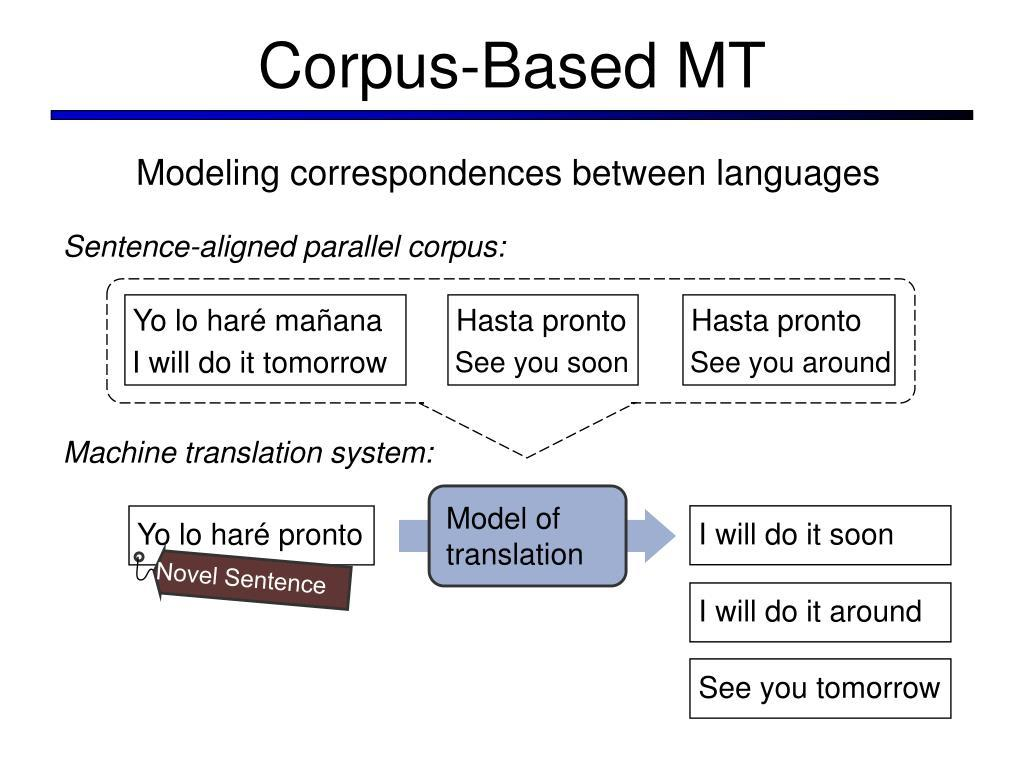

## Why do we need it?

A Seq2Seq translation model needs examples of how sentences in the source language correspond to sentences in the target language.

The parallel corpus provides those examples:

- Input: a sentence in the source language.
- Expected output: its corresponding translation.
- Learning objective: generate target tokens that match the reference translation.

A good corpus should contain accurate translations, suitable language coverage, and examples relevant to the intended domain.

Important: Source and target sentences don't need to contain the same number of words. Their meanings need to correspond.

# 2. Seq2Seq Training Workflow

A Seq2Seq model learns to convert an input sequence into an output sequence. For translation, the encoder processes the source sentence, and the decoder learns to generate the target sentence.



Let's follow one training example.

Source: `I love Tamil`

Target: `நான் தமிழை நேசிக்கிறேன்`

## Step 1 — Prepare the training pair

Take the source sentence and its correct target translation from the parallel corpus.

```
Source: I love Tamil
Target: நான் தமிழை நேசிக்கிறேன்
```

Both sentences are tokenized and converted into numerical token IDs.

Special tokens may be added:

- `<SOS>` — start of sequence
- `<EOS>` — end of sequence
- `<PAD>` — padding for batches of different lengths

## Step 2 — Encoder processes the source


The source token IDs are converted into embeddings. The encoder processes these representations and produces information about the input sentence.

In a basic Seq2Seq model, this information is summarized in a context representation passed to the decoder. The precise form depends on the architecture.

## Step 3 — Decoder learns to predict target tokens

The decoder generates the target sequence one token at a time.

During training, teacher forcing can supply the correct previous target token rather than the decoder's own previous prediction.

For example:

| Decoder input             | Expected prediction |
| ------------------------- | ------------------- |
| `<SOS>`                   | `நான்`              |
| `நான்`                    | `தமிழை`             |
| `நான் தமிழை`              | `நேசிக்கிறேன்`      |
| `நான் தமிழை நேசிக்கிறேன்` | `<EOS>`             |

This table illustrates the training concept; the actual model processes token IDs, not raw strings.

The model learns to predict the next token given the source representation and the preceding target tokens.

## Step 4 — Calculate the loss

The model predicts a probability distribution over possible next tokens. A common training objective is cross-entropy loss, which penalizes the model when it assigns low probability to the correct target token.

Padding positions are normally excluded from the loss calculation.

## Step 5 — Update the model

The training process uses backpropagation to calculate gradients and an optimizer to update the encoder and decoder parameters.

This process repeats over many training examples and batches.

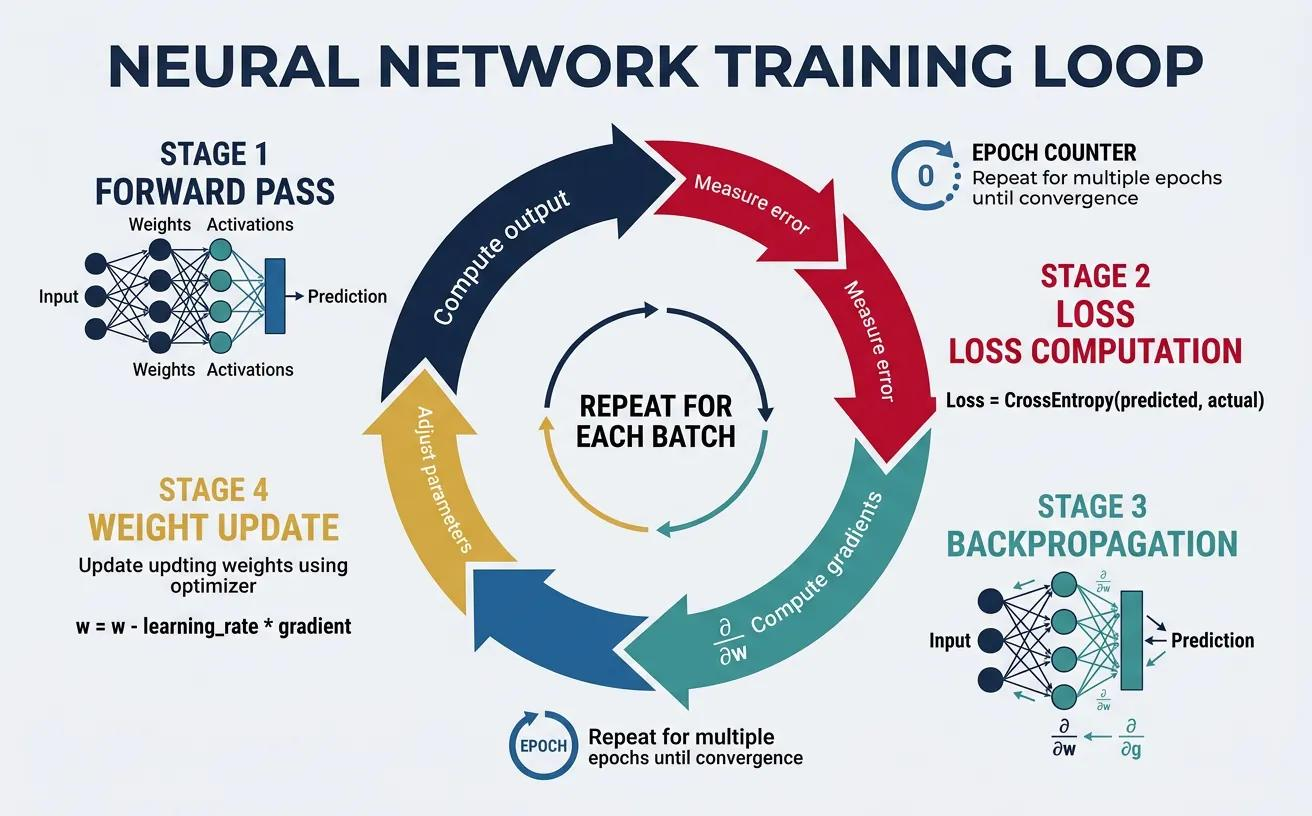

## Step 6 — Inference: translate a new sentence

After training, the model receives a source sentence it has not necessarily seen before.

```
New source sentence
        ↓
     Encoder
        ↓
   Source representation
        ↓
     Decoder
        ↓
  Predict next token
        ↓
 Feed generated token back
        ↓
       Repeat
        ↓
      <EOS>
```

Unlike teacher-forced training, inference uses the model's own generated tokens as the input for subsequent decoding steps. Greedy search or beam search can guide these choices.

## 3. Training vs. inference

| Training                                                     | Inference                                    |
| ------------------------------------------------------------ | -------------------------------------------- |
| Correct source-target pairs are available.                   | A new source sentence is supplied.           |
| Correct target prefixes can be used through teacher forcing. | The model uses its own previous predictions. |
| Loss is calculated and parameters are updated.               | The trained model generates a translation.   |

## What you should remember 🧠

- Parallel corpus: aligned source and target sentences.
- Encoder: processes the source sequence.
- Decoder: learns to generate the target sequence.
- Teacher forcing: supplies correct previous target tokens during training.
- Cross-entropy loss: measures prediction error against target tokens.
- Backpropagation and optimization: update model parameters.
- Inference: generates tokens autoregressively until `<EOS>` or another stopping condition.

---